Initial 2022: 71083 rows, OverallScaleScore range: 150.0 – 600.0
Initial 2023: 71637 rows, OverallScaleScore range: 101.0 – 600.0
Initial 2024: 76539 rows, OverallScaleScore range: 101.0 – 600.0
Summative 2022: 332779 rows, OverallScaleScore range: 201.0 – 1950.0
Summative 2023: 319636 rows, OverallScaleScore range: 201.0 – 1950.0
Summative 2024: 313603 rows, OverallScaleScore range: 201.0 – 1868.0
Saved to elpac_histograms.png


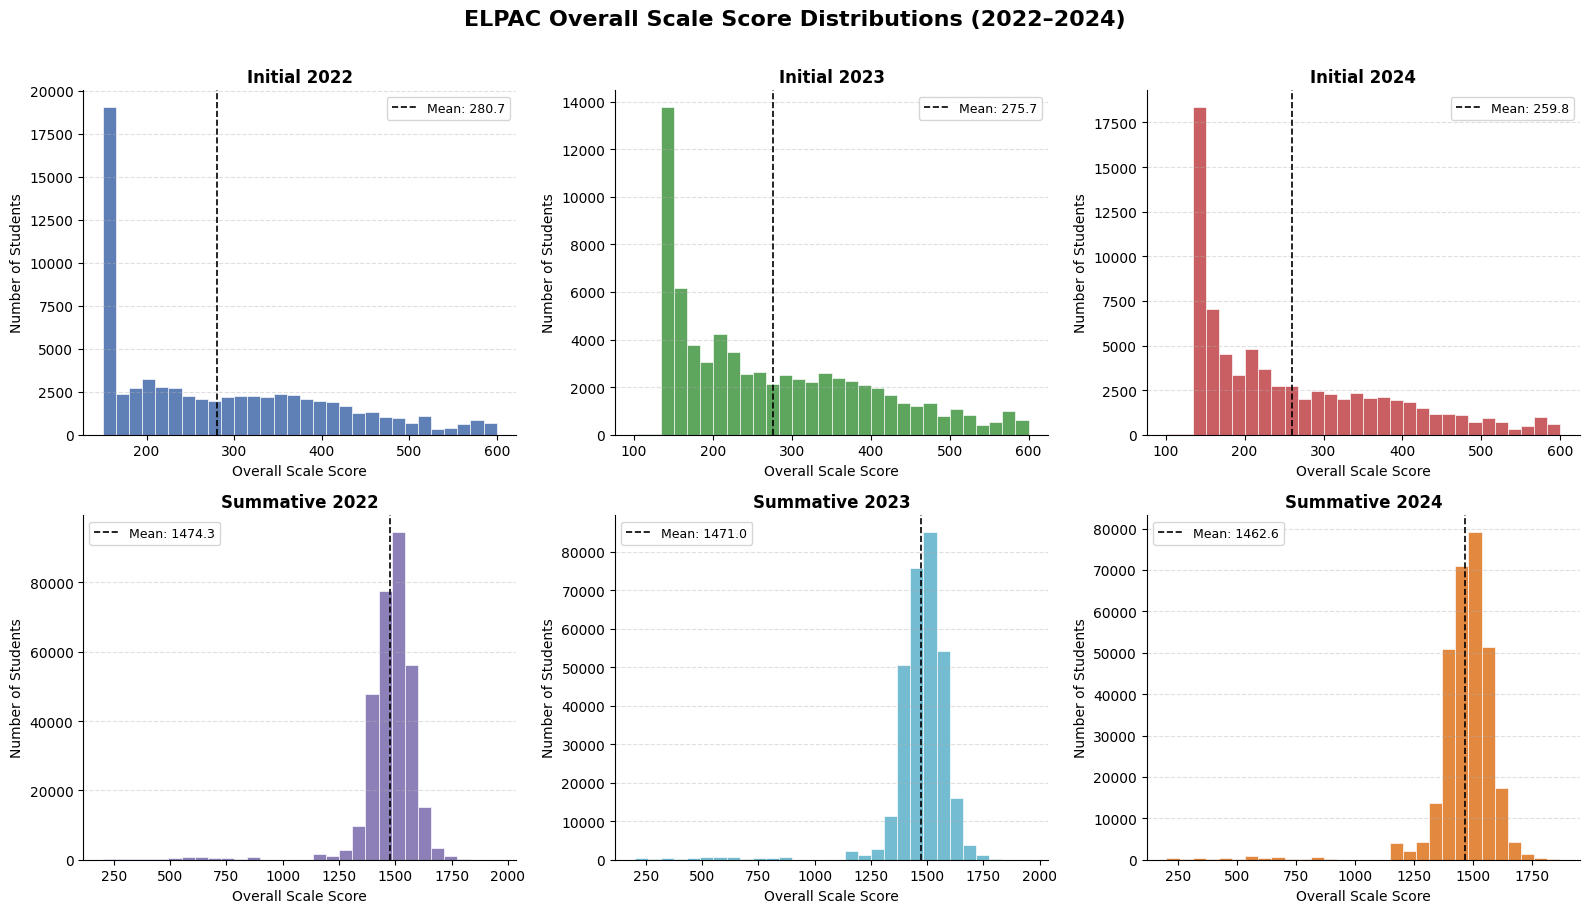

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import os

# --- Load all 6 CSV files ---
data_dir = "../1095 Data/ELPAC/"  # Update this path if your CSVs are in a subfolder

files = {
    "Initial 2022": "InitialElpac_22.csv",
    "Initial 2023": "InitialElpac_23.csv",
    "Initial 2024": "InitialElpac_24.csv",
    "Summative 2022": "SummativeElpac_22.csv",
    "Summative 2023": "SummativeElpac_23.csv",
    "Summative 2024": "SummativeElpac_24.csv",
}

dfs = {}
for label, filename in files.items():
    filepath = os.path.join(data_dir, filename)
    df = pd.read_csv(filepath)
    df["OverallScaleScore"] = pd.to_numeric(df["OverallScaleScore"], errors="coerce")
    dfs[label] = df
    print(f"{label}: {len(df)} rows, OverallScaleScore range: "
          f"{df['OverallScaleScore'].min()} – {df['OverallScaleScore'].max()}")

# --- Plot: 6 histograms in a 2x3 grid ---
colors = {
    "Initial 2022":   "#4C72B0",
    "Initial 2023":   "#4C9B4C",
    "Initial 2024":   "#C44E52",
    "Summative 2022": "#8172B2",
    "Summative 2023": "#64B5CD",
    "Summative 2024": "#E07B2A",
}

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=False)
fig.suptitle("ELPAC Overall Scale Score Distributions (2022–2024)", fontsize=16, fontweight="bold", y=1.01)

for ax, (label, df) in zip(axes.flatten(), dfs.items()):
    scores = df["OverallScaleScore"].dropna()
    ax.hist(scores, bins=30, color=colors[label], edgecolor="white", linewidth=0.5, alpha=0.9)

    # Overlay mean line
    mean_val = scores.mean()
    ax.axvline(mean_val, color="black", linestyle="--", linewidth=1.2, label=f"Mean: {mean_val:.1f}")

    ax.set_title(label, fontsize=12, fontweight="bold")
    ax.set_xlabel("Overall Scale Score", fontsize=10)
    ax.set_ylabel("Number of Students", fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("elpac_histograms.png", dpi=150, bbox_inches="tight")
print("Saved to elpac_histograms.png")
plt.show()


In [23]:
# Strip whitespace from all string columns in ELPAC files
for label in dfs:
    dfs[label] = dfs[label].apply(lambda col: col.str.strip() if col.dtype == "object" else col)

# Count Students

In [13]:
for label, df in dfs.items():
    count = df["SSID"].nunique()
    print(f"{label}: {count} students")

Initial 2022: 62946 students
Initial 2023: 65264 students
Initial 2024: 70231 students
Summative 2022: 302476 students
Summative 2023: 296681 students
Summative 2024: 291920 students


In [14]:
initial_years = ["Initial 2022", "Initial 2023", "Initial 2024"]
summative_years = ["Summative 2022", "Summative 2023", "Summative 2024"]

for init_label in initial_years:
    init_ssids = set(dfs[init_label]["SSID"].dropna())
    print(f"\n{init_label} ({len(init_ssids)} students):")
    for summ_label in summative_years:
        summ_ssids = set(dfs[summ_label]["SSID"].dropna())
        overlap = init_ssids & summ_ssids
        print(f"  → also in {summ_label}: {len(overlap)} students")


Initial 2022 (62946 students):
  → also in Summative 2022: 52175 students
  → also in Summative 2023: 45655 students
  → also in Summative 2024: 37349 students

Initial 2023 (65264 students):
  → also in Summative 2022: 47 students
  → also in Summative 2023: 55309 students
  → also in Summative 2024: 47101 students

Initial 2024 (70231 students):
  → also in Summative 2022: 11 students
  → also in Summative 2023: 17 students
  → also in Summative 2024: 60536 students


In [15]:
from collections import Counter

# Count how many initial years each SSID appears in
ssid_year_count = Counter()

for label in ["Initial 2022", "Initial 2023", "Initial 2024"]:
    for ssid in dfs[label]["SSID"].dropna().unique():
        ssid_year_count[ssid] += 1

# Bucket by number of years
years_distribution = Counter(ssid_year_count.values())

print("Initial ELPAC — Students by Number of Years Present:")
for num_years in sorted(years_distribution):
    print(f"  {num_years} year(s): {years_distribution[num_years]} students")
    

Initial ELPAC — Students by Number of Years Present:
  1 year(s): 195577 students
  2 year(s): 1393 students
  3 year(s): 26 students


In [16]:
ssid_year_count_summ = Counter()

for label in ["Summative 2022", "Summative 2023", "Summative 2024"]:
    for ssid in dfs[label]["SSID"].dropna().unique():
        ssid_year_count_summ[ssid] += 1

years_distribution_summ = Counter(ssid_year_count_summ.values())

print("Summative ELPAC — Students by Number of Years Present:")
for num_years in sorted(years_distribution_summ):
    print(f"  {num_years} year(s): {years_distribution_summ[num_years]} students")

Summative ELPAC — Students by Number of Years Present:
  1 year(s): 152236 students
  2 year(s): 117335 students
  3 year(s): 168057 students


In [17]:
# Build per-student year counts for initial and summative
initial_labels = ["Initial 2022", "Initial 2023", "Initial 2024"]
summative_labels = ["Summative 2022", "Summative 2023", "Summative 2024"]

initial_year_count = Counter()
for label in initial_labels:
    for ssid in dfs[label]["SSID"].dropna().unique():
        initial_year_count[ssid] += 1

summative_year_count = Counter()
for label in summative_labels:
    for ssid in dfs[label]["SSID"].dropna().unique():
        summative_year_count[ssid] += 1

# Get all SSIDs that appear in at least one initial AND one summative file
all_ssids = set(initial_year_count.keys()) & set(summative_year_count.keys())

# Count combinations
combo_counts = Counter()
for ssid in all_ssids:
    combo = (initial_year_count[ssid], summative_year_count[ssid])
    combo_counts[combo] += 1

print("Students by (Initial Years, Summative Years):")
for init_n in [1, 2, 3]:
    for summ_n in [1, 2, 3]:
        count = combo_counts.get((init_n, summ_n), 0)
        print(f"  {init_n} initial / {summ_n} summative: {count} students")

Students by (Initial Years, Summative Years):
  1 initial / 1 summative: 78668 students
  1 initial / 2 summative: 54962 students
  1 initial / 3 summative: 35213 students
  2 initial / 1 summative: 447 students
  2 initial / 2 summative: 738 students
  2 initial / 3 summative: 14 students
  3 initial / 1 summative: 11 students
  3 initial / 2 summative: 1 students
  3 initial / 3 summative: 0 students


In [20]:
# Get all SSIDs with initial data and their first OverallPL value
initial_oral_pl = {}
for label in ["Initial 2022", "Initial 2023", "Initial 2024"]:
    for _, row in dfs[label][["SSID", "OverallPL"]].dropna().iterrows():
        if row["SSID"] not in initial_oral_pl:
            initial_oral_pl[row["SSID"]] = row["OverallPL"]

# Group by OralLanguagePL and count summative years
from collections import defaultdict

results = defaultdict(lambda: Counter())

for ssid, oral_pl in initial_oral_pl.items():
    summ_count = summative_year_count.get(ssid, 0)
    results[oral_pl][summ_count] += 1

# Display results
print("Students with Initial Data — Summative Years by OverallPL:")
for pl in sorted(results.keys()):
    total = sum(results[pl].values())
    print(f"\n  OverallPL = {pl} ({total} students):")
    for summ_n in [0, 1, 2, 3]:
        count = results[pl].get(summ_n, 0)
        print(f"    {summ_n} summative year(s): {count} students")

Students with Initial Data — Summative Years by OverallPL:

  OverallPL =                                          (1544 students):
    0 summative year(s): 711 students
    1 summative year(s): 307 students
    2 summative year(s): 523 students
    3 summative year(s): 3 students

  OverallPL = Initial Fluent English Proficient (IFEP) (21272 students):
    0 summative year(s): 21259 students
    1 summative year(s): 9 students
    2 summative year(s): 4 students
    3 summative year(s): 0 students

  OverallPL = Intermediate English Learner             (24692 students):
    0 summative year(s): 473 students
    1 summative year(s): 12161 students
    2 summative year(s): 7617 students
    3 summative year(s): 4441 students

  OverallPL = NS                                       (835 students):
    0 summative year(s): 450 students
    1 summative year(s): 164 students
    2 summative year(s): 217 students
    3 summative year(s): 4 students

  OverallPL = Novice English Learner       

In [22]:
# Show all unique OverallPL values across all initial files
print("Unique OverallPL values in Initial ELPAC files:\n")
for label in ["Initial 2022", "Initial 2023", "Initial 2024"]:
    unique_vals = dfs[label]["OverallPL"].dropna().unique()
    print(f"  {label}: {sorted(unique_vals)}")

# Combined across all years
all_pl_values = set()
for label in ["Initial 2022", "Initial 2023", "Initial 2024"]:
    all_pl_values.update(dfs[label]["OverallPL"].dropna().unique())

print(f"\nAll unique values across all initial files:")
for val in sorted(all_pl_values):
    print(f"  '{val}'")

Unique OverallPL values in Initial ELPAC files:

  Initial 2022: ['                                        ', 'Initial Fluent English Proficient (IFEP)', 'Intermediate English Learner            ', 'NS                                      ', 'Novice English Learner                  ']
  Initial 2023: ['                                        ', 'Initial Fluent English Proficient (IFEP)', 'Intermediate English Learner            ', 'NS                                      ', 'Novice English Learner                  ']
  Initial 2024: ['                                        ', 'Initial Fluent English Proficient (IFEP)', 'Intermediate English Learner            ', 'NS                                      ', 'Novice English Learner                  ']

All unique values across all initial files:
  '                                        '
  'Initial Fluent English Proficient (IFEP)'
  'Intermediate English Learner            '
  'NS                                      '
  'Novice Engli

In [25]:
# --- Group A: Initial OverallPL = "Novice English Learner" with 3 summative years ---
# --- Group B: Initial OverallPL = "Intermediate English Learner" with 3 summative years ---

# Step 1: Find SSIDs with 3 summative years
ssids_3_summative = {ssid for ssid, count in summative_year_count.items() if count == 3}
print(f"Students with 3 summative years: {len(ssids_3_summative):,}")

# Step 2: Build a lookup of SSID -> initial OverallPL (use earliest year available)
initial_overall_pl = {}
for label in ["Initial 2022", "Initial 2023", "Initial 2024"]:
    for _, row in dfs[label][["SSID", "OverallPL"]].dropna().iterrows():
        if row["SSID"] not in initial_overall_pl:
            initial_overall_pl[row["SSID"]] = row["OverallPL"].strip()

# Step 3: Filter by PL level AND 3 summative years
group_a_ssids = {
    ssid for ssid, pl in initial_overall_pl.items()
    if pl == "Novice English Learner" and ssid in ssids_3_summative
}

group_b_ssids = {
    ssid for ssid, pl in initial_overall_pl.items()
    if pl == "Intermediate English Learner" and ssid in ssids_3_summative
}

print(f"\nGroup A (Novice + 3 summative years):       {len(group_a_ssids):,} students")
print(f"Group B (Intermediate + 3 summative years): {len(group_b_ssids):,} students")

# Step 4: Export to CSV
pd.DataFrame({"SSID": list(group_a_ssids)}).to_csv("group_a_ssids.csv", index=False)
pd.DataFrame({"SSID": list(group_b_ssids)}).to_csv("group_b_ssids.csv", index=False)

print("\nSaved: group_a_ssids.csv")
print("Saved: group_b_ssids.csv")

Students with 3 summative years: 168,057

Group A (Novice + 3 summative years):       30,779 students
Group B (Intermediate + 3 summative years): 4,441 students

Saved: group_a_ssids.csv
Saved: group_b_ssids.csv
